# Vector database benchmark — results

Reads the CSVs written by `bench.runner` and `bench.esci_eval` and produces every
figure and table used in the report. Re-run with `make notebook` after any benchmark run.

* **Systems run** — SIFT1M (`results/sift1m`): recall vs speed, latency, memory, build and update cost.
* **ESCI run** — 1.8M Amazon products in 3 languages (`results/esci`): the same metrics on real
  product embeddings, plus retrieval quality sliced by language and product category.

If the full runs are missing, the notebook falls back to the smoke runs and says so in a banner.

In [1]:
import json, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = ROOT / "results"

def pick(*names):
    for n in names:
        if (R / n / "sweep.csv").exists():
            return R / n
    return None

SYS = pick("sift1m", "synthetic1m", "smoke")
ESCI = pick("esci", "esci_smoke")
SMOKE = any(p is not None and "smoke" in p.name for p in (SYS, ESCI))
if SMOKE:
    display(Markdown("> **Smoke data — not for reporting.** Showing `" + ", ".join(
        p.name for p in (SYS, ESCI) if p) + "`. Run `make sift1m` and `make esci` for real numbers."))

def load(run, name):
    p = run / f"{name}.csv" if run else None
    return pd.read_csv(p) if p is not None and p.exists() else pd.DataFrame()

# Colour follows the engine everywhere (fixed categorical order, validated palette).
COLORS = {"faiss_hnsw": "#2a78d6", "pgvector_hnsw": "#eb6834", "qdrant_hnsw": "#1baf7a",
          "milvus_hnsw": "#eda100", "faiss_ivf": "#e87ba4", "pgvector_hnsw_iter": "#008300",
          "faiss_flat": "#6250d6", "exact": "#6250d6"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "font.size": 10, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.titlecolor": INK, "legend.frameon": False})
FIG = R / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=200)

def op_points(sweep, target):
    """Fastest setting reaching the recall target (else the most accurate one), per engine."""
    rc = [c for c in sweep.columns if c.startswith("recall@") and c != "recall@1"][0]
    out = []
    for eng, g in sweep.groupby("engine"):
        ok = g[g[rc] >= target]
        out.append(ok.loc[ok.lat_p50_ms.idxmin()] if len(ok) else g.loc[g[rc].idxmax()])
    return pd.DataFrame(out).reset_index(drop=True), rc

## Environment
Hardware and library versions are captured with every run, so results can be compared fairly.

In [2]:
for run in (SYS, ESCI):
    if run and (run / "env.json").exists():
        e = json.load(open(run / "env.json"))
        print(f"--- {run.name}: n_base={e['n_base']:,}  holdout={e['n_holdout']:,}  deletes={e['n_delete']:,}")
        print({k: v for k, v in e["env"].items()})

--- sift1m: n_base=990,000  holdout=10,000  deletes=10,000
{'python': '3.14.6', 'platform': 'Windows-11-10.0.26200-SP0', 'cpu': 'AMD64 Family 26 Model 112 Stepping 0, AuthenticAMD', 'cpu_count': 32, 'ram_gb': 123.6, 'numpy': '2.5.3', 'timestamp': '2026-11-01T17:51:50+0530', 'faiss': '1.15.1', 'qdrant_client': '?', 'pymilvus': '3.0.2', 'psycopg': '3.3.6', 'pgvector': '?'}
--- esci: n_base=1,796,775  holdout=18,149  deletes=18,149
{'python': '3.14.6', 'platform': 'Windows-11-10.0.26200-SP0', 'cpu': 'AMD64 Family 26 Model 112 Stepping 0, AuthenticAMD', 'cpu_count': 32, 'ram_gb': 123.6, 'numpy': '2.5.3', 'timestamp': '2026-11-01T21:48:47+0530', 'faiss': '1.15.1', 'qdrant_client': '?', 'pymilvus': '3.0.2', 'psycopg': '3.3.6', 'pgvector': '?'}


## 1. Recall vs throughput
Each point is one search setting (`ef` for HNSW, `nprobe` for IVF). Up and to the right is better.
The dashed line is the recall target used to pick each engine's operating point.
FAISS runs in-process; the database engines pay a network round trip per query, which is part of
what you pay in production.

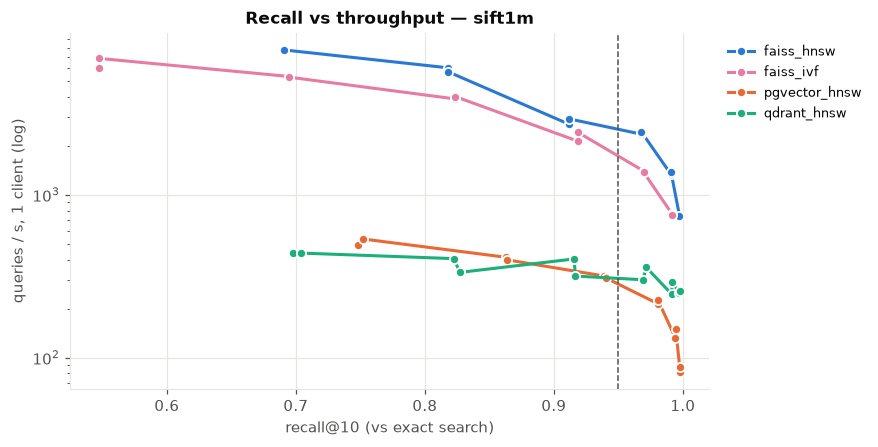

engine,faiss_hnsw,faiss_ivf,pgvector_hnsw,qdrant_hnsw
param,,,,
ef=10,0.6908,NaN,0.7500,0.7008
ef=160,0.9908,NaN,0.9944,0.9915
ef=20,0.8181,NaN,0.8632,0.8248
ef=320,0.9974,NaN,0.9980,0.9976
ef=40,0.9121,NaN,0.9399,0.9162
ef=80,0.9679,NaN,0.9804,0.9704
nprobe=128,NaN,0.9914,NaN,NaN
nprobe=16,NaN,0.8236,NaN,NaN
nprobe=32,NaN,0.9184,NaN,NaN


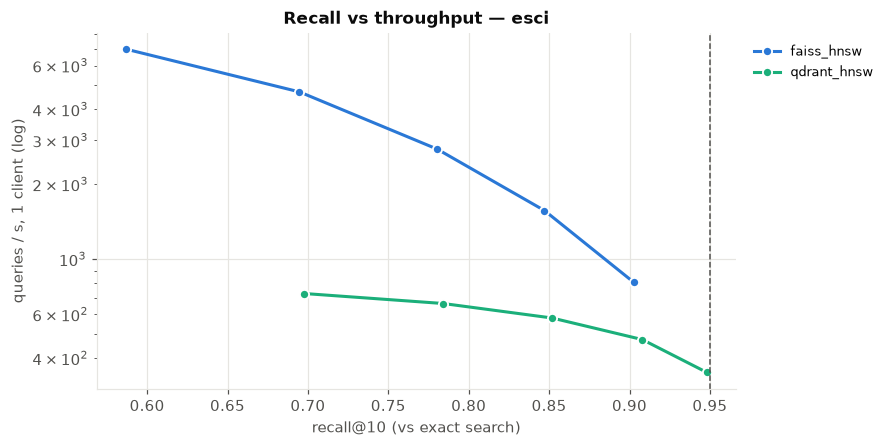

engine,faiss_hnsw,qdrant_hnsw
param,,
ef=160,0.8471,0.9080
ef=20,0.5867,0.6977
ef=320,0.9027,0.9482
ef=40,0.6947,0.7842
ef=80,0.7804,0.8519


In [3]:
def pareto_plot(run, title, fname):
    sw = load(run, "sweep")
    if sw.empty: return
    target = json.load(open(run / "env.json"))["config"].get("recall_target", 0.95)
    rc = [c for c in sw.columns if c.startswith("recall@") and c != "recall@1"][0]
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for eng, g in sw.groupby("engine", sort=False):
        if eng == "faiss_flat": continue
        g = g.sort_values(rc)
        ax.plot(g[rc], g.qps_1thread, "-o", lw=2, ms=6, color=COLORS.get(eng, INK2), label=eng,
                markeredgecolor="white", markeredgewidth=1.2)
    ax.axvline(target, ls="--", lw=1, color=INK2)
    ax.set_yscale("log"); ax.set_xlabel(rc + " (vs exact search)"); ax.set_ylabel("queries / s, 1 client (log)")
    ax.set_title(title); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5)
    save(fig, fname); plt.show()
    display(sw.pivot_table(index="param", columns="engine", values=rc).round(4))

pareto_plot(SYS, f"Recall vs throughput — {SYS.name if SYS else ''}", "pareto_systems")
if ESCI: pareto_plot(ESCI, f"Recall vs throughput — {ESCI.name}", "pareto_esci")

## 2. Latency at the operating point
Operating point = the fastest setting that reaches the recall target. The dot is the median,
the bar runs to p99 (tail latency is what users notice).

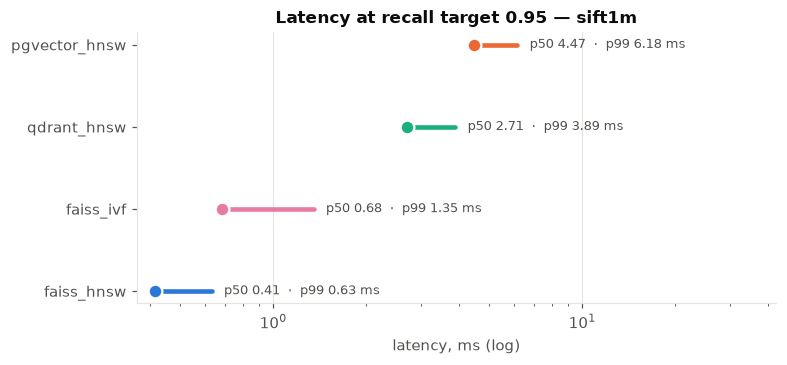

,engine,param,recall@10,recall@1,lat_p50_ms,lat_p95_ms,lat_p99_ms,qps_1thread,in_process
0,faiss_hnsw,ef=80,0.968,0.981,0.414,0.497,0.633,2431.540,True
1,faiss_ivf,nprobe=64,0.970,0.986,0.684,1.042,1.353,1372.523,True
3,qdrant_hnsw,ef=80,0.972,0.984,2.711,3.370,3.890,359.557,False
2,pgvector_hnsw,ef=80,0.980,0.984,4.472,5.359,6.175,227.340,False


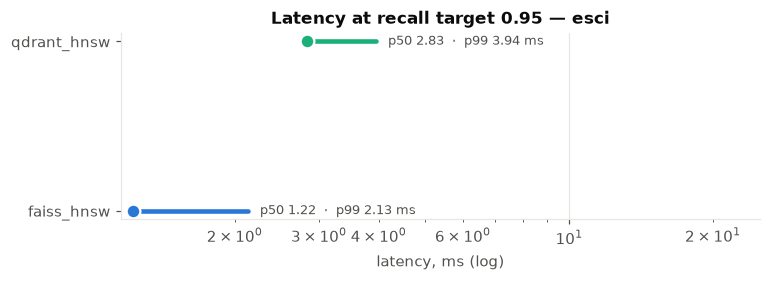

,engine,param,recall@10,recall@1,lat_p50_ms,lat_p95_ms,lat_p99_ms,qps_1thread,in_process
0,faiss_hnsw,ef=320,0.903,0.895,1.224,1.712,2.128,807.046,True
1,qdrant_hnsw,ef=320,0.948,0.930,2.834,3.511,3.944,350.639,False


In [4]:
def latency_plot(run, fname):
    sw = load(run, "sweep")
    if sw.empty: return pd.DataFrame()
    target = json.load(open(run / "env.json"))["config"].get("recall_target", 0.95)
    op, rc = op_points(sw, target)
    op = op.sort_values("lat_p50_ms")
    fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(op) + 1.2))
    for i, r in enumerate(op.itertuples()):
        c = COLORS.get(r.engine, INK2)
        ax.plot([r.lat_p50_ms, r.lat_p99_ms], [i, i], lw=3, color=c, solid_capstyle="round")
        ax.plot(r.lat_p50_ms, i, "o", ms=9, color=c, markeredgecolor="white", markeredgewidth=1.5)
        ax.annotate(f"p50 {r.lat_p50_ms:.2f}  ·  p99 {r.lat_p99_ms:.2f} ms", (r.lat_p99_ms, i),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(range(len(op)), op.engine); ax.set_xscale("log"); ax.set_xlabel("latency, ms (log)")
    ax.set_title(f"Latency at recall target {target} — {run.name}"); ax.grid(axis="y", visible=False)
    ax.set_xlim(right=ax.get_xlim()[1] * 6)
    save(fig, fname); plt.show()
    cols = ["engine", "param", rc, "recall@1", "lat_p50_ms", "lat_p95_ms", "lat_p99_ms", "qps_1thread", "in_process"]
    return op[cols].round(3)

display(latency_plot(SYS, "latency_systems"))
if ESCI: display(latency_plot(ESCI, "latency_esci"))

## 3. Build cost and memory
`index_mb` is what the engine reports for its index (FAISS serialised size, pgvector `pg_relation_size`).
`rss_delta_mb` is the measured growth of the server process (or container) after the build, which
also captures caches and graph overhead; Qdrant and Milvus only expose this one.

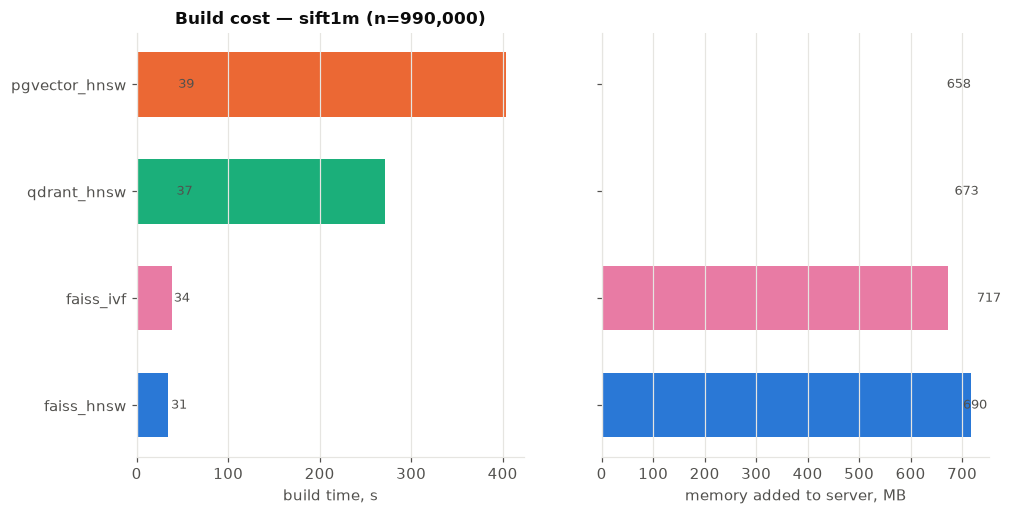

,engine,build_total_s,load_s,index_s,index_mb,rss_delta_mb,rss_peak_delta_mb,bytes_per_vector,table_mb
0,faiss_hnsw,30.8,0.0,30.6,627.2,689.9,1156.0,664.3,NaN
4,faiss_hnsw,33.9,0.0,33.7,627.2,716.8,1181.2,664.3,NaN
1,faiss_ivf,36.8,0.0,10.7,508.1,673.4,1162.7,538.2,NaN
5,faiss_ivf,38.7,0.0,11.0,508.1,658.3,1116.3,538.2,NaN
7,qdrant_hnsw,238.3,20.1,217.9,NaN,NaN,NaN,NaN,NaN
3,qdrant_hnsw,271.0,21.6,249.0,NaN,NaN,NaN,NaN,NaN
6,pgvector_hnsw,374.9,6.0,368.6,774.5,NaN,NaN,820.4,1348.4
2,pgvector_hnsw,403.4,6.8,396.3,774.5,NaN,NaN,820.3,1348.4


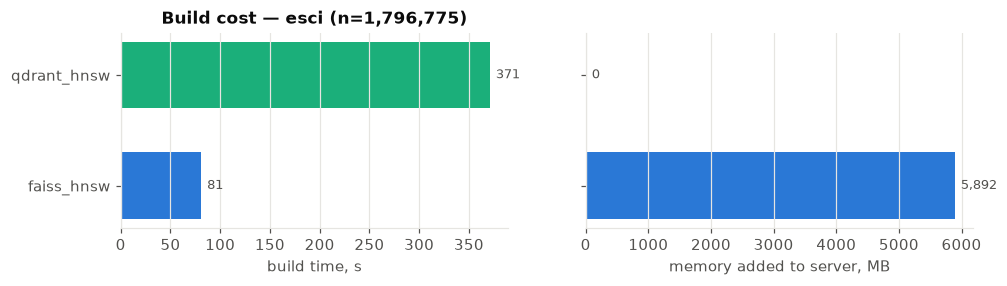

,engine,build_total_s,load_s,index_s,index_mb,rss_delta_mb,rss_peak_delta_mb,bytes_per_vector
0,faiss_hnsw,80.7,0.0,79.5,2892.9,5891.7,8295.2,1688.3
1,qdrant_hnsw,370.9,84.8,284.7,NaN,NaN,NaN,NaN


In [5]:
def build_view(run, fname):
    b = load(run, "build")
    if b.empty: return
    b = b[b.engine != "faiss_flat"].sort_values("build_total_s")
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.45 * len(b) + 1.4), sharey=True)
    for ax, col, lab in ((axes[0], "build_total_s", "build time, s"),
                         (axes[1], "rss_delta_mb", "memory added to server, MB")):
        vals = b[col].fillna(0)
        ax.barh(b.engine, vals, color=[COLORS.get(e, INK2) for e in b.engine], height=0.6)
        for y, v in enumerate(vals):
            ax.annotate(f"{v:,.0f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center",
                        fontsize=8.5, color=INK2)
        ax.set_xlabel(lab); ax.grid(axis="y", visible=False)
    axes[0].set_title(f"Build cost — {run.name} (n={int(b.n.iloc[0]):,})")
    save(fig, fname); plt.show()
    cols = [c for c in ["engine", "build_total_s", "load_s", "index_s", "index_mb", "rss_delta_mb",
                        "rss_peak_delta_mb", "bytes_per_vector", "table_mb"] if c in b]
    display(b[cols].round(1))

build_view(SYS, "build_systems")
if ESCI: build_view(ESCI, "build_esci")

## 4. Index update cost
1% of vectors were held out of the build and inserted afterwards, then 1% were deleted.
`insert_to_searchable_s` includes waiting for background indexing (Qdrant, Milvus).
`recall_after_delete` checks the index did not degrade; `deleted_returned_rate` checks deleted
products never come back in results. FAISS HNSW has no real delete, so it filters tombstones
and needs a full rebuild to reclaim space.

In [6]:
for run in (SYS, ESCI):
    u = load(run, "update")
    if u.empty: continue
    cols = [c for c in ["engine", "insert_vps", "insert_to_searchable_s", "delete_vps", "vacuum_s",
                        "delete_native", "recall_before", "recall_after_insert", "recall_after_delete",
                        "deleted_returned_rate"] if c in u]
    print(run.name); display(u[u.engine != "faiss_flat"][cols].round(4))

sift1m


,engine,insert_vps,insert_to_searchable_s,delete_vps,vacuum_s,delete_native,recall_before,recall_after_insert,recall_after_delete,deleted_returned_rate
0,faiss_hnsw,4929.8789,2.0285,338879.6638,NaN,False,0.9679,0.9683,0.9687,0.0
1,faiss_ivf,56005.9053,0.1786,284342.9403,NaN,True,0.9697,0.9700,0.9698,0.0
2,pgvector_hnsw,132.8008,75.3007,35345.7807,665.7837,True,0.9805,0.9805,0.9807,0.0
3,qdrant_hnsw,17725.3297,0.7708,89873.3415,NaN,True,0.9715,0.9719,0.9703,0.0
4,faiss_hnsw,5048.0055,1.9810,352543.4246,NaN,False,0.9679,0.9683,0.9687,0.0
5,faiss_ivf,50049.0982,0.1998,278118.4729,NaN,True,0.9697,0.9700,0.9698,0.0
6,pgvector_hnsw,193.3408,51.7221,40252.0260,647.7282,True,0.9804,0.9804,0.9808,0.0
7,qdrant_hnsw,20330.6454,0.6651,82139.0993,NaN,True,0.9692,0.9695,0.9686,0.0


esci


,engine,insert_vps,insert_to_searchable_s,delete_vps,delete_native,recall_before,recall_after_insert,recall_after_delete,deleted_returned_rate
0,faiss_hnsw,4713.9475,3.8501,279431.1915,False,0.9027,0.9021,0.9020,0.0
1,qdrant_hnsw,15732.4078,11.6480,100059.2670,True,0.9482,0.9486,0.9481,0.0


## 5. Throughput under concurrency
Same operating point, several clients in parallel.

In [7]:
for run in (SYS, ESCI):
    c = load(run, "concurrency")
    if not c.empty:
        print(run.name); display(c[["engine", "clients", "qps", "lat_p50_ms", "lat_p99_ms"]].round(2))

sift1m


,engine,clients,qps,lat_p50_ms,lat_p99_ms
0,faiss_hnsw,8,9938.63,0.56,1.07
1,faiss_ivf,8,5632.10,1.27,2.41
2,pgvector_hnsw,8,674.90,6.34,53.29
3,qdrant_hnsw,8,1497.91,4.97,9.31
4,faiss_hnsw,8,9672.77,0.52,1.50
5,faiss_ivf,8,5431.66,1.29,2.90
6,pgvector_hnsw,8,923.09,4.86,48.09
7,qdrant_hnsw,8,1540.75,4.76,9.26


esci


,engine,clients,qps,lat_p50_ms,lat_p99_ms
0,faiss_hnsw,8,4007.81,1.83,3.18
1,qdrant_hnsw,8,664.74,11.85,16.56


## 6. Filtered search: “only show products from my store”
Each query is restricted to its own locale. US is ~67% of the catalogue, Japan ~19%, Spain ~14%,
so the filter is most selective for the smallest market. `underfilled_rate` = share of queries that
got fewer than 10 results back: the customer simply sees a shorter, worse list.

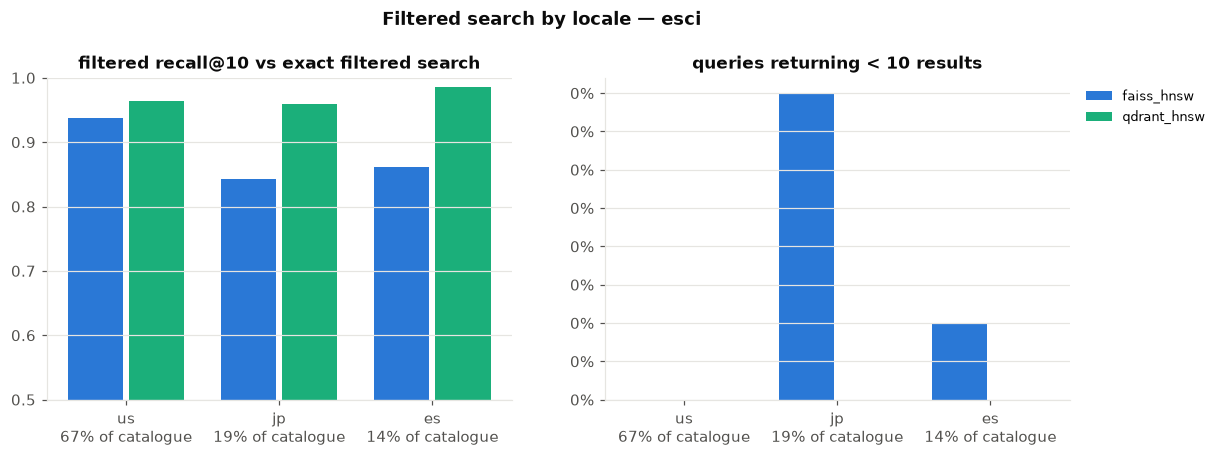

recall@10                      underfilled_rate                   
locale            ALL     es     jp     us              ALL     es     jp   us
engine                                                                        
faiss_hnsw       0.88  0.861  0.843  0.938            0.002  0.001  0.004  0.0
qdrant_hnsw      0.97  0.986  0.959  0.964            0.000  0.000  0.000  0.0

In [8]:
def filtered_view(run, fname):
    f = load(run, "filtered")
    if f.empty: return
    f = f[f.engine != "faiss_flat"]
    rc = [c for c in f.columns if c.startswith("recall@")][0]
    locs = [l for l in ["us", "jp", "es"] if l in set(f.locale)]
    engines = list(dict.fromkeys(f.engine))
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    w = 0.8 / len(engines)
    for j, eng in enumerate(engines):
        g = f[f.engine == eng].set_index("locale")
        x = np.arange(len(locs)) + (j - (len(engines) - 1) / 2) * w
        for ax, col in ((axes[0], rc), (axes[1], "underfilled_rate")):
            ax.bar(x, g.loc[locs, col], width=w * 0.9, color=COLORS.get(eng, INK2), label=eng)
    share = f.drop_duplicates("locale").set_index("locale").locale_share
    for ax, t in ((axes[0], f"filtered {rc} vs exact filtered search"),
                  (axes[1], "queries returning < 10 results")):
        ax.set_xticks(range(len(locs)), [f"{l}\n{share[l]:.0%} of catalogue" for l in locs])
        ax.set_title(t); ax.grid(axis="x", visible=False)
    axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    axes[0].set_ylim(min(0.5, f[rc].min() - 0.05), 1.0)
    axes[1].legend(fontsize=8.5, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.suptitle(f"Filtered search by locale — {run.name}", fontweight="bold", color=INK, y=1.04)
    save(fig, fname); plt.show()
    display(f.pivot_table(index="engine", columns="locale", values=[rc, "underfilled_rate"]).round(3))

filtered_view(SYS, "filtered_systems")
if ESCI: filtered_view(ESCI, "filtered_esci")

## 7. Responsible AI: is search equally good across languages and categories?
Quality is measured against **human relevance labels** (ESCI: Exact / Substitute / Complement / Irrelevant),
for exact search and for every engine at its operating point. Error bars are 95% bootstrap intervals.

Two separate questions:
1. **Model gap** — does the embedding model serve some languages/categories worse? (visible in `exact`)
2. **Engine gap** — does the ANN index or filter strategy *add* to that gap? (engine minus exact, per slice)

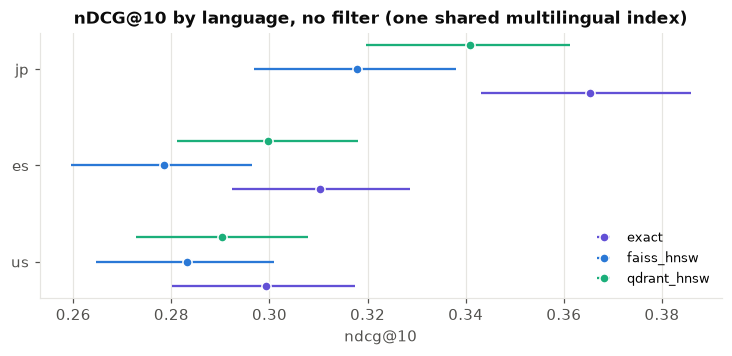

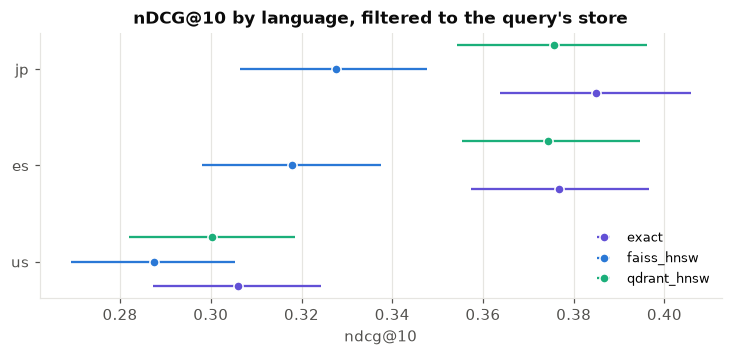

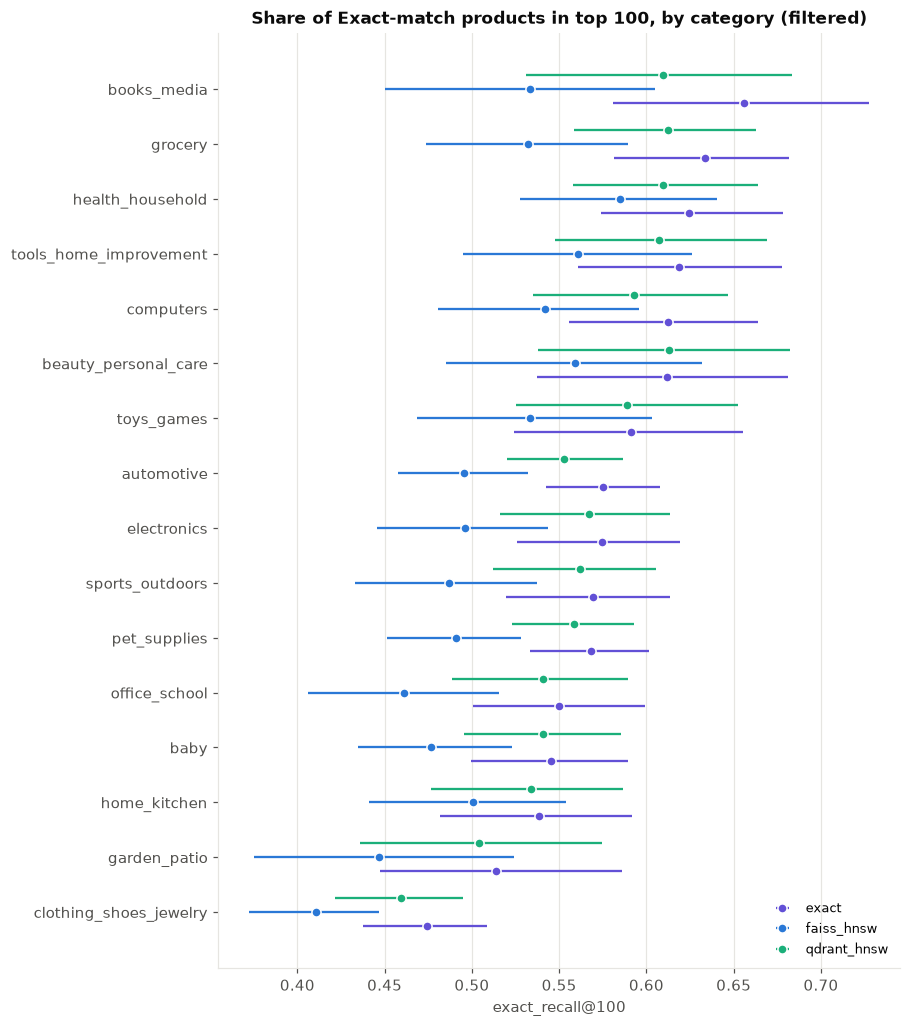

In [9]:
S = pd.read_csv(ESCI / "esci_slices.csv") if ESCI and (ESCI / "esci_slices.csv").exists() else pd.DataFrame()
D = pd.read_csv(ESCI / "esci_disparity.csv") if ESCI and (ESCI / "esci_disparity.csv").exists() else pd.DataFrame()

def slice_dots(metric, mode, slice_type, fname, title):
    s = S[(S["mode"] == mode) & (S.slice_type == slice_type) & ~S.small_slice]
    if s.empty: return
    engines = ["exact"] + [e for e in dict.fromkeys(s.engine) if e != "exact"]
    order = (s[s.engine == "exact"].sort_values(metric).slice.tolist())
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(order) * (1 + 0.15 * len(engines)) + 1.3))
    h = 0.75 / len(engines)
    for j, eng in enumerate(engines):
        g = s[s.engine == eng].set_index("slice").reindex(order)
        y = np.arange(len(order)) + (j - (len(engines) - 1) / 2) * h
        ax.errorbar(g[metric], y, xerr=[g[metric] - g[f"{metric}_lo"], g[f"{metric}_hi"] - g[metric]],
                    fmt="o", ms=6, lw=1.5, capsize=0, color=COLORS.get(eng, INK2), label=eng,
                    markeredgecolor="white", markeredgewidth=1)
    ax.set_yticks(range(len(order)), order); ax.set_xlabel(metric); ax.grid(axis="y", visible=False)
    ax.set_title(title); ax.legend(fontsize=8.5, loc="lower right")
    save(fig, fname); plt.show()

if not S.empty:
    slice_dots("ndcg@10", "unfiltered", "locale", "ndcg_locale_unfiltered",
               "nDCG@10 by language, no filter (one shared multilingual index)")
    slice_dots("ndcg@10", "filtered", "locale", "ndcg_locale_filtered",
               "nDCG@10 by language, filtered to the query's store")
    slice_dots("exact_recall@100", "filtered", "category", "exact_recall_category",
               "Share of Exact-match products in top 100, by category (filtered)")

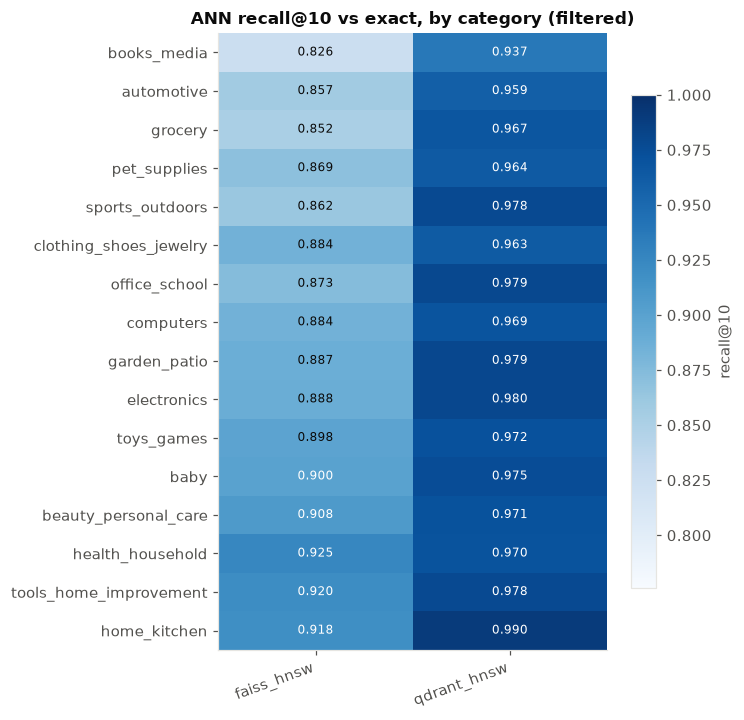

In [10]:
# Index fidelity per category: does the ANN index lose more neighbours in some categories?
if not S.empty:
    s = S[(S["mode"] == "filtered") & (S.slice_type == "category") & ~S.small_slice & (S.engine != "exact")]
    if not s.empty:
        M = s.pivot_table(index="slice", columns="engine", values="ann_recall@10")
        M = M.loc[M.mean(axis=1).sort_values().index]
        fig, ax = plt.subplots(figsize=(1.6 * M.shape[1] + 2.5, 0.38 * len(M) + 1.2))
        im = ax.imshow(M.values, cmap="Blues", vmin=max(0.0, np.nanmin(M.values) - 0.05), vmax=1.0, aspect="auto")
        for (i, j), v in np.ndenumerate(M.values):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if v > im.norm.vmin + 0.55 * (im.norm.vmax - im.norm.vmin) else INK)
        ax.set_xticks(range(M.shape[1]), M.columns, rotation=20, ha="right"); ax.set_yticks(range(len(M)), M.index)
        ax.grid(False); ax.set_title("ANN recall@10 vs exact, by category (filtered)")
        fig.colorbar(im, ax=ax, shrink=0.8, label="recall@10")
        save(fig, "ann_recall_category"); plt.show()

### Disparity summary
`gap` = best slice minus worst slice. For engines, `gap_added_by_engine` is how much of that gap the
index/filter adds on top of exact search (positive = the engine makes the disparity worse).

In [11]:
if not D.empty:
    cols = [c for c in ["engine", "mode", "slice_type", "metric", "worst_slice", "worst", "best_slice", "best",
                        "gap", "gap_exact", "gap_added_by_engine", "ann_loss_max_slice", "ann_loss_max"] if c in D]
    display(D[D.metric.isin(["ndcg@10", "ann_recall@10"])][cols].round(4))
if not S.empty:
    leak = S[(S["mode"] == "unfiltered") & (S.slice_type == "locale")][["engine", "slice", "foreign@10"]]
    display(Markdown("**Cross-store leakage without a filter** — share of top-10 results from another locale:"))
    display(leak.pivot(index="engine", columns="slice", values="foreign@10").round(3))

,engine,mode,slice_type,metric,worst_slice,worst,best_slice,best,gap,gap_exact,gap_added_by_engine,ann_loss_max_slice,ann_loss_max
0,exact,filtered,category,ndcg@10,clothing_shoes_jewelry,0.2603,books_media,0.4672,0.2069,NaN,NaN,NaN,NaN
2,exact,filtered,category,ann_recall@10,automotive,1.0000,automotive,1.0000,0.0000,NaN,NaN,NaN,NaN
3,exact,filtered,locale,ndcg@10,us,0.3059,jp,0.3850,0.0791,NaN,NaN,NaN,NaN
5,exact,filtered,locale,ann_recall@10,es,1.0000,es,1.0000,0.0000,NaN,NaN,NaN,NaN
6,exact,unfiltered,category,ndcg@10,clothing_shoes_jewelry,0.2310,grocery,0.4319,0.2008,NaN,NaN,NaN,NaN
8,exact,unfiltered,category,ann_recall@10,automotive,1.0000,automotive,1.0000,0.0000,NaN,NaN,NaN,NaN
9,exact,unfiltered,locale,ndcg@10,us,0.2993,jp,0.3653,0.0661,NaN,NaN,NaN,NaN
11,exact,unfiltered,locale,ann_recall@10,es,1.0000,es,1.0000,0.0000,NaN,NaN,NaN,NaN
12,faiss_hnsw,filtered,category,ndcg@10,clothing_shoes_jewelry,0.2258,grocery,0.3902,0.1644,0.2069,-0.0425,books_media,0.0834
14,faiss_hnsw,filtered,category,ann_recall@10,books_media,0.8260,health_household,0.9253,0.0993,NaN,NaN,NaN,NaN


**Cross-store leakage without a filter** — share of top-10 results from another locale:

slice,es,jp,us
engine,,,
exact,0.265,0.143,0.047
faiss_hnsw,0.290,0.184,0.048
qdrant_hnsw,0.266,0.152,0.047


## 8. Inputs to the selection guide
One row per engine, at its operating point, on the main systems run.

In [12]:
def scorecard(run):
    sw = load(run, "sweep")
    if sw.empty: return pd.DataFrame()
    target = json.load(open(run / "env.json"))["config"].get("recall_target", 0.95)
    op, rc = op_points(sw, target)
    sc = op[["engine", "param", rc, "lat_p50_ms", "lat_p99_ms", "qps_1thread"]].set_index("engine")
    b, u, f = load(run, "build"), load(run, "update"), load(run, "filtered")
    if not b.empty: sc = sc.join(b.set_index("engine")[["build_total_s", "rss_delta_mb"]])
    if not u.empty: sc = sc.join(u.set_index("engine")[["insert_vps", "insert_to_searchable_s", "delete_native"]])
    if not f.empty:
        fa = f[f.locale == "ALL"].set_index("engine")
        sc = sc.join(fa[[c for c in fa.columns if c.startswith("recall@")] + ["underfilled_rate"]]
                     .rename(columns=lambda c: "filtered_" + c))
    return sc.drop(index="faiss_flat", errors="ignore").round(3)

for run in (SYS, ESCI):
    if run: print(run.name); display(scorecard(run))

sift1m


,param,recall@10,lat_p50_ms,lat_p99_ms,qps_1thread,build_total_s,rss_delta_mb,insert_vps,insert_to_searchable_s,delete_native
engine,,,,,,,,,,
faiss_hnsw,ef=80,0.968,0.414,0.633,2431.540,30.780,689.852,4929.879,2.028,False
faiss_hnsw,ef=80,0.968,0.414,0.633,2431.540,30.780,689.852,5048.006,1.981,False
faiss_hnsw,ef=80,0.968,0.414,0.633,2431.540,33.882,716.773,4929.879,2.028,False
faiss_hnsw,ef=80,0.968,0.414,0.633,2431.540,33.882,716.773,5048.006,1.981,False
faiss_ivf,nprobe=64,0.970,0.684,1.353,1372.523,36.812,673.398,56005.905,0.179,True
faiss_ivf,nprobe=64,0.970,0.684,1.353,1372.523,36.812,673.398,50049.098,0.200,True
faiss_ivf,nprobe=64,0.970,0.684,1.353,1372.523,38.672,658.305,56005.905,0.179,True
faiss_ivf,nprobe=64,0.970,0.684,1.353,1372.523,38.672,658.305,50049.098,0.200,True
pgvector_hnsw,ef=80,0.980,4.472,6.175,227.340,403.378,NaN,132.801,75.301,True


esci


,param,recall@10,lat_p50_ms,lat_p99_ms,qps_1thread,build_total_s,rss_delta_mb,insert_vps,insert_to_searchable_s,delete_native,filtered_recall@10,filtered_underfilled_rate
engine,,,,,,,,,,,,
faiss_hnsw,ef=320,0.903,1.224,2.128,807.046,80.733,5891.719,4713.947,3.850,False,0.88,0.002
qdrant_hnsw,ef=320,0.948,2.834,3.944,350.639,370.948,NaN,15732.408,11.648,True,0.97,0.000
